# 08 - Decision Tree Models (Regression + Classification)

**Goal:** Train Decision Trees on the video game sales data, tune them, evaluate them properly, and compare with the baselines from notebook 07.

### What is a Decision Tree?
A flowchart of yes/no questions learned from data. At every step the tree picks the question (e.g. *"Is Platform = PS2?"*) that best separates the classes.
- **Unpruned tree** -> keeps splitting until it memorises the training data (**overfitting**).
- **Pruned / tuned tree** -> limited with `max_depth` and `min_samples_leaf`, so it generalises better.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, r2_score, mean_absolute_error, mean_squared_error)

df = pd.read_csv("feature_engineered_dataset.csv")
print(df.shape)
df.head()

(16291, 6)


,Platform,Year,Genre,Publisher,Global_Sales,Sales_Category
0,Wii,2006,Sports,Nintendo,82.74,Hit
1,NES,1985,Platform,Nintendo,40.24,Hit
2,Wii,2008,Racing,Nintendo,35.82,Hit
3,Wii,2009,Sports,Nintendo,33.00,Hit
4,GB,1996,Role-Playing,Nintendo,31.37,Hit


## 1. Prepare data (same steps as notebook 07, so results are comparable)

In [2]:
# Group rare publishers -> top 15 + "Other"
top_publishers = df['Publisher'].value_counts().nlargest(15).index
df['Publisher_Grouped'] = df['Publisher'].where(df['Publisher'].isin(top_publishers), 'Other')

# One-hot encode the categorical features
X = pd.get_dummies(df[['Platform', 'Year', 'Genre', 'Publisher_Grouped']],
                   columns=['Platform', 'Genre', 'Publisher_Grouped'], drop_first=True)

# Targets
class_names = ['Flop', 'Average', 'Hit']
y_class = df['Sales_Category'].map({'Flop': 0, 'Average': 1, 'Hit': 2})
y_reg = df['Global_Sales']

# Same split as notebook 07 (80/20, random_state=42)
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_class, y_reg, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (13032, 57)  Test: (3259, 57)


## 2. Baselines (what must a decision tree beat?)
A model is only useful if it beats the **majority-class baseline** (always predict the most common class).

In [3]:
results = []   # (model, accuracy, macro-F1)

def log_result(name, y_true, y_pred):
    results.append((name, accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average='macro')))

# Majority class baseline
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, yc_train)
log_result('Majority-class baseline', yc_test, dummy.predict(X_test))

# Logistic Regression (scale Year only, fit scaler on train only)
Xtr_l, Xte_l = X_train.copy(), X_test.copy()
sc = StandardScaler()
Xtr_l['Year'] = sc.fit_transform(Xtr_l[['Year']])
Xte_l['Year'] = sc.transform(Xte_l[['Year']])
log_model = LogisticRegression(max_iter=1000).fit(Xtr_l, yc_train)
log_result('Logistic Regression', yc_test, log_model.predict(Xte_l))

# KNN (scale all features)
sc2 = StandardScaler()
knn = KNeighborsClassifier(n_neighbors=15).fit(sc2.fit_transform(X_train), yc_train)
log_result('KNN (k=15)', yc_test, knn.predict(sc2.transform(X_test)))

pd.DataFrame(results, columns=['Model', 'Accuracy', 'Macro F1']).round(4)

,Model,Accuracy,Macro F1
0,Majority-class baseline,0.4879,0.2186
1,Logistic Regression,0.5707,0.4595
2,KNN (k=15),0.5710,0.4963


## 3. Decision Tree Classifier

### 3.1 Unpruned tree - see overfitting

In [4]:
dt_full = DecisionTreeClassifier(random_state=42).fit(X_train, yc_train)
print("Depth of unpruned tree :", dt_full.get_depth())
print("Number of leaves       :", dt_full.get_n_leaves())
print(f"Train accuracy: {dt_full.score(X_train, yc_train):.4f}")
print(f"Test  accuracy: {dt_full.score(X_test, yc_test):.4f}")
# Big gap between train and test accuracy = OVERFITTING

Depth of unpruned tree : 43
Number of leaves       : 4255
Train accuracy: 0.7769
Test  accuracy: 0.5554


### 3.2 Tune the tree with GridSearchCV (5-fold cross-validation)

In [5]:
param_grid = {
    'max_depth': [3, 5, 7, 10, 15],
    'min_samples_leaf': [5, 20, 50],
    'criterion': ['gini', 'entropy']
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                    cv=5, scoring='f1_macro', n_jobs=-1)
grid.fit(X_train, yc_train)

print("Best parameters :", grid.best_params_)
print(f"Best CV macro-F1: {grid.best_score_:.4f}")
dt_best = grid.best_estimator_
y_pred_dt = dt_best.predict(X_test)
print(f"Train accuracy  : {dt_best.score(X_train, yc_train):.4f}")
print(f"Test  accuracy  : {accuracy_score(yc_test, y_pred_dt):.4f}")
log_result('Decision Tree (tuned)', yc_test, y_pred_dt)

Best parameters : {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 5}
Best CV macro-F1: 0.4837
Train accuracy  : 0.6229
Test  accuracy  : 0.5643


### 3.3 Detailed evaluation: precision / recall / F1 and confusion matrix

              precision    recall  f1-score   support

        Flop       0.62      0.83      0.71      1590
     Average       0.37      0.22      0.27       861
         Hit       0.54      0.42      0.47       808

    accuracy                           0.56      3259
   macro avg       0.51      0.49      0.48      3259
weighted avg       0.53      0.56      0.53      3259



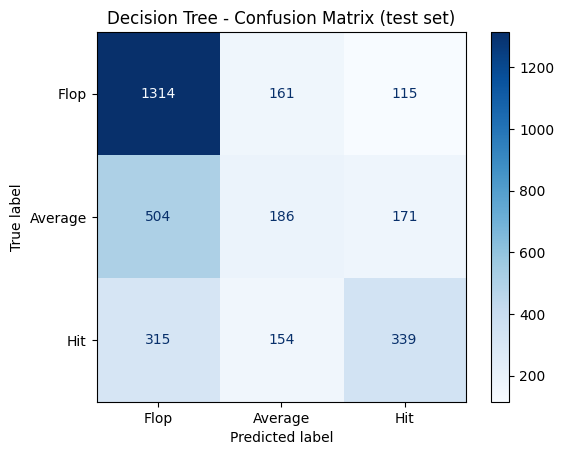

In [6]:
print(classification_report(yc_test, y_pred_dt, target_names=class_names))

cm = confusion_matrix(yc_test, y_pred_dt)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues')
plt.title("Decision Tree - Confusion Matrix (test set)")
plt.show()

### 3.4 Visualise a small tree (depth 3) - easy to explain in an interview
The tuned tree is too deep to read, so we train a depth-3 tree purely for **interpretation**.

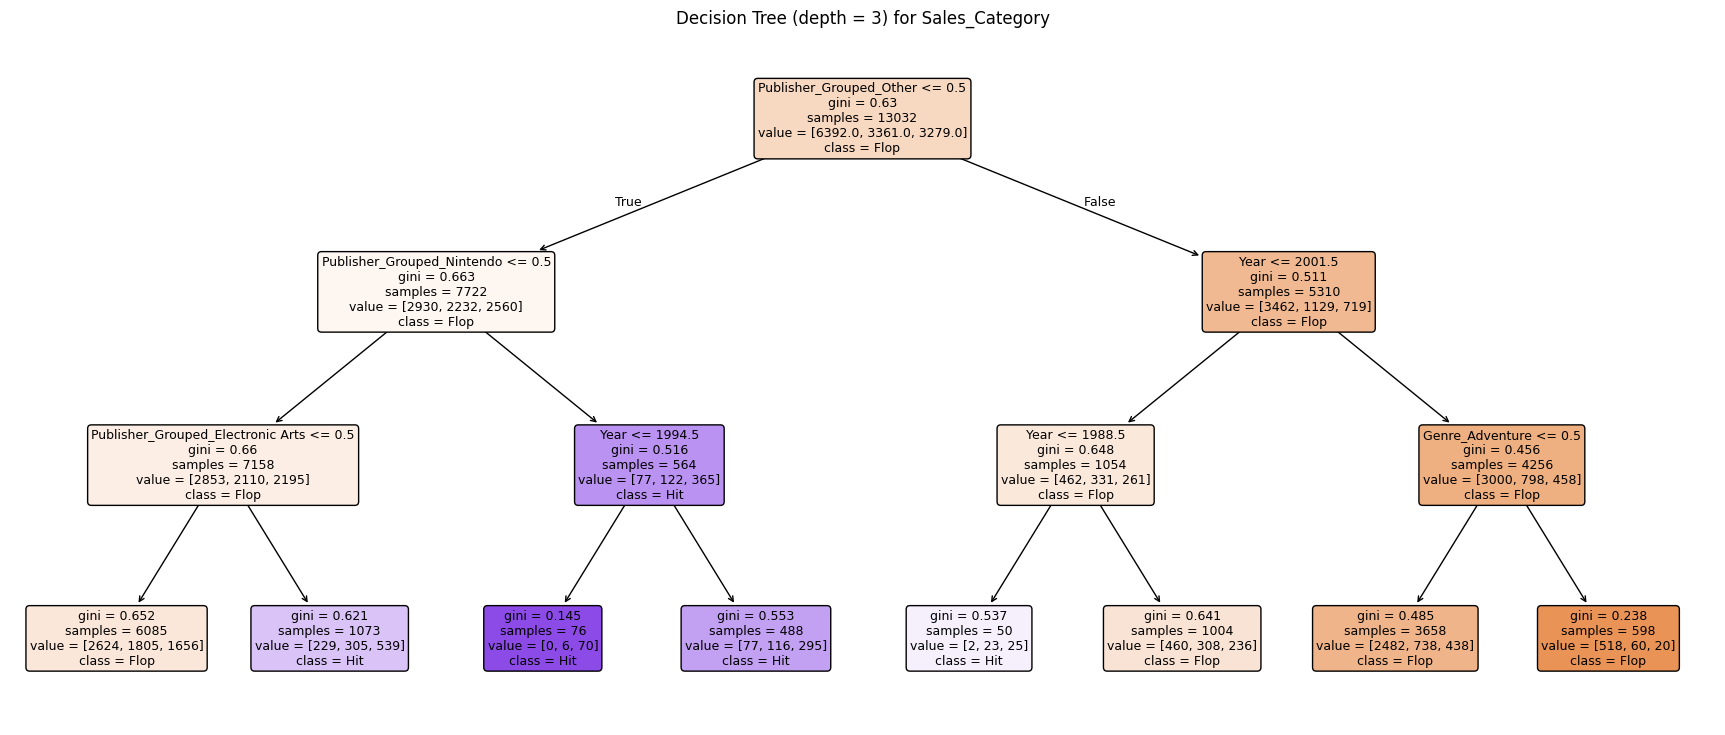

|--- Publisher_Grouped_Other <= 0.50
|   |--- Publisher_Grouped_Nintendo <= 0.50
|   |   |--- Publisher_Grouped_Electronic Arts <= 0.50
|   |   |   |--- class: 0
|   |   |--- Publisher_Grouped_Electronic Arts >  0.50
|   |   |   |--- class: 2
|   |--- Publisher_Grouped_Nintendo >  0.50
|   |   |--- Year <= 1994.50
|   |   |   |--- class: 2
|   |   |--- Year >  1994.50
|   |   |   |--- class: 2
|--- Publisher_Grouped_Other >  0.50
|   |--- Year <= 2001.50
|   |   |--- Year <= 1988.50
|   |   |   |--- class: 2
|   |   |--- Year >  1988.50
|   |   |   |--- class: 0
|   |--- Year >  2001.50
|   |   |--- Genre_Adventure <= 0.50
|   |   |   |--- class: 0
|   |   |--- Genre_Adventure >  0.50
|   |   |   |--- class: 0



In [7]:
dt_small = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=42).fit(X_train, yc_train)
plt.figure(figsize=(22, 9))
plot_tree(dt_small, feature_names=X.columns, class_names=class_names,
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (depth = 3) for Sales_Category")
plt.show()

print(export_text(dt_small, feature_names=list(X.columns)))

### 3.5 Feature importance - which inputs drive the prediction?

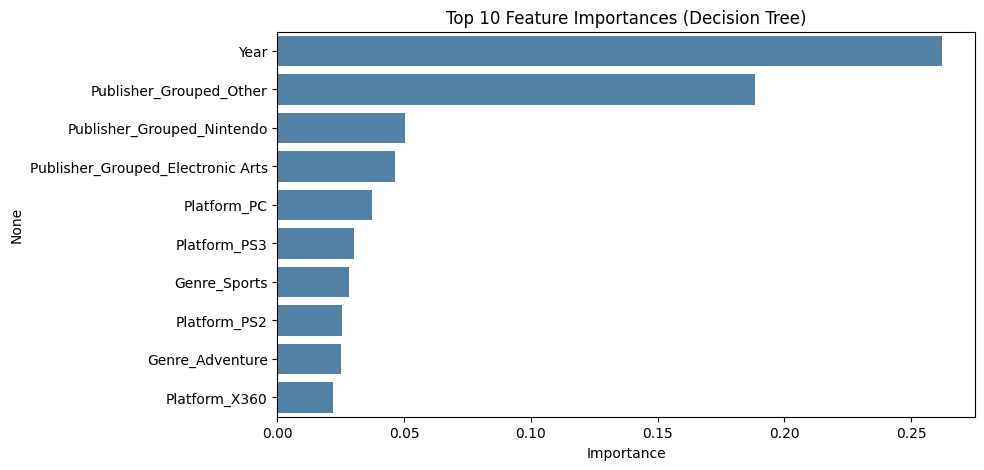

Year                                 0.262130
Publisher_Grouped_Other              0.188289
Publisher_Grouped_Nintendo           0.050334
Publisher_Grouped_Electronic Arts    0.046298
Platform_PC                          0.037325
Platform_PS3                         0.030390
Genre_Sports                         0.028121
Platform_PS2                         0.025328
Genre_Adventure                      0.025085
Platform_X360                        0.021849
dtype: float64

In [8]:
imp = pd.Series(dt_best.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=imp.values, y=imp.index, color='steelblue')
plt.title("Top 10 Feature Importances (Decision Tree)")
plt.xlabel("Importance")
plt.show()
imp

## 4. Decision Tree Regressor (predict Global_Sales in millions)
Same idea, but each leaf predicts a **number** (average sales of games in that leaf). We train on `log1p(sales)` because sales are heavily right-skewed.

In [9]:
reg_grid = GridSearchCV(DecisionTreeRegressor(random_state=42),
                        {'max_depth': [3, 5, 7, 10], 'min_samples_leaf': [5, 20, 50]},
                        cv=5, scoring='r2', n_jobs=-1)
reg_grid.fit(X_train, np.log1p(yr_train))
dt_reg = reg_grid.best_estimator_
print("Best parameters:", reg_grid.best_params_)

pred_log = dt_reg.predict(X_test)
pred = np.expm1(pred_log)

print(f"R2 (log scale)      : {r2_score(np.log1p(yr_test), pred_log):.4f}")
print(f"R2 (original scale) : {r2_score(yr_test, pred):.4f}")
print(f"MAE (millions)      : {mean_absolute_error(yr_test, pred):.4f}")
print(f"RMSE (millions)     : {np.sqrt(mean_squared_error(yr_test, pred)):.4f}")

# Compare with the Linear Regression baseline from notebook 07
lin = LinearRegression().fit(X_train, np.log1p(yr_train))
lin_log = lin.predict(X_test)
print("\nLinear Regression baseline:")
print(f"R2 (log scale)      : {r2_score(np.log1p(yr_test), lin_log):.4f}")
print(f"R2 (original scale) : {r2_score(yr_test, np.expm1(lin_log)):.4f}")
print(f"MAE (millions)      : {mean_absolute_error(yr_test, np.expm1(lin_log)):.4f}")

Best parameters: {'max_depth': 10, 'min_samples_leaf': 20}
R2 (log scale)      : 0.1755
R2 (original scale) : 0.0558
MAE (millions)      : 0.4925
RMSE (millions)     : 2.0097

Linear Regression baseline:
R2 (log scale)      : 0.2210
R2 (original scale) : 0.0536
MAE (millions)      : 0.4829


## 5. Final comparison table (classification)

In [10]:
comparison = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Macro F1']).round(4)
comparison.sort_values('Macro F1', ascending=False).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,KNN (k=15),0.5710,0.4963
1,Decision Tree (tuned),0.5643,0.4840
2,Logistic Regression,0.5707,0.4595
3,Majority-class baseline,0.4879,0.2186


## 6. Conclusions (be honest in the interview)

- The **unpruned** tree overfits badly: ~78% train accuracy vs ~56% test accuracy (depth 43, 4,255 leaves). Limiting `max_depth` / `min_samples_leaf` reduces the gap.
- The **tuned** tree gets ~56% accuracy / macro-F1 ~0.48. That is about the **same** as Logistic Regression and KNN (~57%), and all of them beat the ~49% majority-class baseline only modestly. The tree does **not** clearly win on accuracy.
- Per class: the tree is good at spotting **Flops** (recall ~0.83) but weak on the middle **Average** class (recall ~0.22). Average games look like both Flops and Hits when you only know platform/genre/year/publisher.
- **Regression:** the tuned Decision Tree Regressor (R2 on log scale ~0.18) is actually **worse** than plain Linear Regression (~0.22). On the original scale both are ~0.05 because a few blockbusters dominate the error.
- Why the ceiling is low: the features are only metadata. Review scores, budget, marketing and franchise strength are missing.
- Why still use a tree: it is **interpretable** (readable rules, feature importance, class probabilities).

**Next steps:** Random Forest / XGBoost, extra features (e.g. publisher track record computed on training data only), time-based split.